# AlphaEarth neural codec — demo

A learned pyramidal RVQ codec for the AlphaEarth Foundations embedding
tiles (64-band unit-norm vectors, 10 m grid). One 2.25 GB source tile
compresses to a ~58 MB directory of **georeferenced COG assets** at
cosine fidelity ~0.998 — with progressive quality, windowed/ranged
access, per-tile error metadata, and exact nodata + geo round-trip.

| asset | contents |
|---|---|
| `coarse/mid/fine.tif` | RVQ code indices; **bands = quantizer levels** |
| `star.tif` | 2-bit coarse-residual refinement (outlier insurance) |
| `mask.tif` | validity (exact nodata restore) |
| `quality/<decoder>.tif` | measured per-window error, per rate point |
| `metadata.json` | source profile, quality stats, bitstream id |

This notebook: original → PCA visualization → encode → look at the
codes → progressive decode → a client/server demo with rate-control and
quality-control fetches → the two decoders (plain vs deblock) and their
separate quality layers.

In [1]:
import json, os, subprocess, sys, time
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window

sys.path.insert(0, "..")                     # georvq (run from notebooks/)
from georvq.ae.cli import TorchBackend, prep_ae_np, unpack_star
from georvq.inference.api import Packet

# ---- config ----------------------------------------------------------
TILE = "/data/AE-samples/tiles_full/2019/55S/xx9gre8yvyf4ii6o4-0000000000-0000008192.tiff"
TILE_S3 = ("s3://us-west-2.opendata.source.coop/tge-labs/aef/v1/annual/"
           "2019/xx9gre8yvyf4ii6o4-0000000000-0000008192.tiff")
BUNDLE = os.environ.get("GEORVQ_AE_BUNDLE",
                        "/data/georvq-releases/ae-beta-v1/bundle")
ASSETS = f"/tmp/ae_demo_assets_{os.environ.get('USER', 'shared')}"
DEVICE = "cuda:1"

if not os.path.exists(TILE):                 # download if not mirrored
    TILE = "/tmp/ae_demo_tile.tiff"
    if not os.path.exists(TILE):
        env = {**os.environ, "AWS_NO_SIGN_REQUEST": "YES"}
        subprocess.run(["aws", "s3", "cp", TILE_S3, TILE], env=env,
                       check=True)
print("source tile:", TILE, f"({os.path.getsize(TILE)/2**30:.2f} GiB)")

source tile: /data/AE-samples/tiles_full/2019/55S/xx9gre8yvyf4ii6o4-0000000000-0000008192.tiff (2.25 GiB)


## 1. The original embeddings

AlphaEarth pixels are 64-d unit vectors (int8, signed-square quantized).
We look at a 1024 px crop through the lens of its top principal
components — PCA is fit once on the original and reused for every
reconstruction below, so colors are comparable throughout.

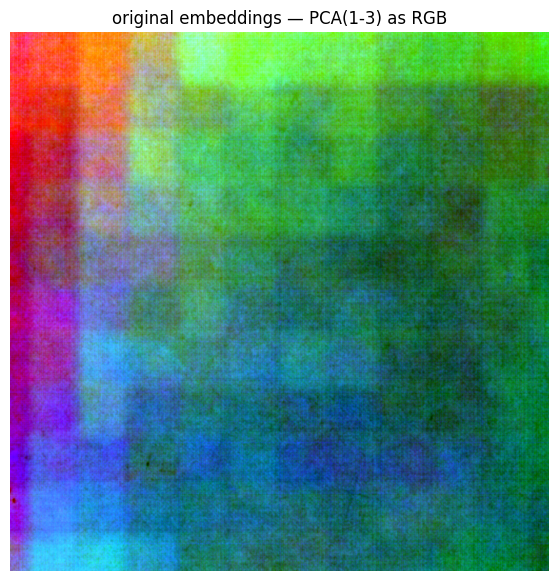

In [2]:
CROP = (3072, 4096)          # row, col of a 1024px crop, NORTH-UP frame
os.environ["GDAL_NUM_THREADS"] = "ALL_CPUS"
with rasterio.open(TILE) as ds:
    bottom_up = ds.transform.e > 0           # AEF tiles store rows south-up
    # the codec assets are north-up; convert the north-up crop row to the
    # file's row offset so original and decoded panels show the SAME ground
    row_off = ds.height - CROP[0] - 1024 if bottom_up else CROP[0]
    raw = ds.read(window=Window(CROP[1], row_off, 1024, 1024))
if bottom_up:                                # model convention: north-up
    raw = raw[:, ::-1, :]
x0, valid0 = prep_ae_np(raw[None].astype(np.int8))
x0, valid0 = x0[0], valid0[0]                # (64, 1024, 1024), (1024, 1024)

flat = x0.reshape(64, -1).T
samp = flat[np.random.default_rng(0).choice(len(flat), 20000, replace=False)]
mu = samp.mean(0)
_, _, VT = np.linalg.svd(samp - mu, full_matrices=False)

def pca_rgb(x):
    """(64, H, W) -> PCA dims 1-3 as RGB, robust-scaled."""
    p = np.tensordot(VT[:3], x - mu[:, None, None], axes=(1, 0))
    lo, hi = np.percentile(p, [2, 98], axis=(1, 2), keepdims=True)
    return np.clip((p - lo) / (hi - lo), 0, 1).transpose(1, 2, 0)

plt.figure(figsize=(7, 7)); plt.imshow(pca_rgb(x0))
plt.title("original embeddings — PCA(1-3) as RGB"); plt.axis("off");

## 2. Encode

One command turns the tile into the COG asset directory. The encoder
also *measures itself*: it decodes every rate-ladder point and records
true error statistics into `metadata.json` and a per-window quality
raster (that's what quality-control decode uses later). ~80 s on an
A100; add `--no-stats` for ~35 s.

In [3]:
t0 = time.time()
if not os.path.exists(f"{ASSETS}/metadata.json"):
    subprocess.run([sys.executable, "-m", "georvq.ae.cli", "tile",
                    "encode", "--model", BUNDLE, "--device", DEVICE,
                    "--batch", "256", TILE, ASSETS],
                   check=True, cwd="..")
    print(f"encoded in {time.time()-t0:.0f}s")
for root, _, files in os.walk(ASSETS):
    for f in sorted(files):
        p = os.path.join(root, f)
        print(f"{os.path.relpath(p, ASSETS):32s} {os.path.getsize(p)/2**20:8.2f} MiB")
print(f"{'SOURCE':32s} {os.path.getsize(TILE)/2**20:8.2f} MiB")

coarse.tif                           0.18 MiB
fine.tif                            53.54 MiB
mask.tif                             0.07 MiB
metadata.json                        0.00 MiB
mid.tif                              3.01 MiB
star.tif                             1.05 MiB
quality/c9779727ec46de60.tif         0.21 MiB
quality/fba6e990f327dc75.tif         0.21 MiB
SOURCE                            2300.37 MiB


## 3. What the codes look like

The assets are real rasters: the coarse tier is a 128×128, 8-band,
640 m/cell categorical map (one 11-bit code per 64 px window per level).
Codes are *labels*, not measurements — never interpolate them — but
mapped to random colors they show the codec carving the landscape into
its learned vocabulary.

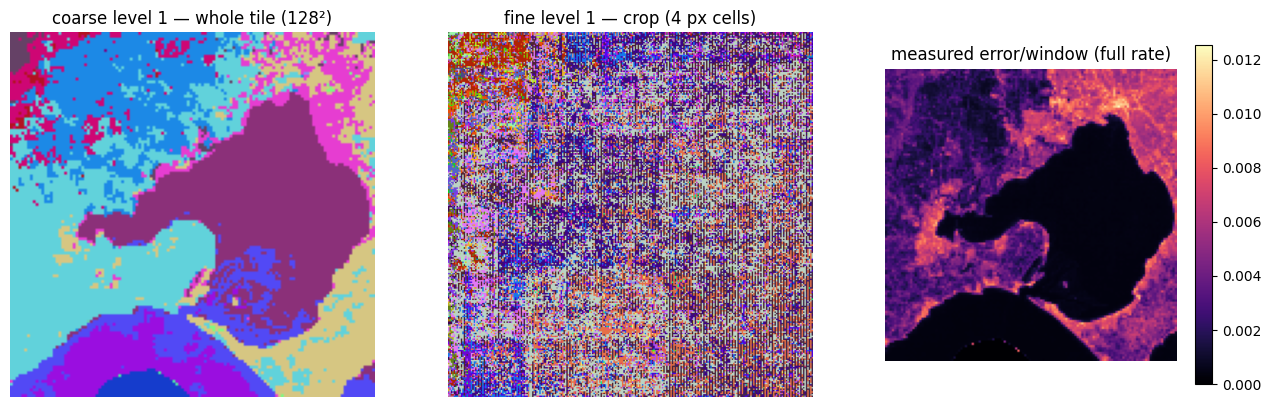

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
rng = np.random.default_rng(3)
with rasterio.open(f"{ASSETS}/coarse.tif") as ds:
    c1 = ds.read(1)
lut = rng.random((2048, 3))
ax[0].imshow(lut[c1]); ax[0].set_title("coarse level 1 — whole tile (128²)")
with rasterio.open(f"{ASSETS}/fine.tif") as ds:
    f1 = ds.read(1, window=Window(CROP[1]//4, CROP[0]//4, 256, 256))
lut16 = rng.random((16384, 3))
ax[1].imshow(lut16[f1]); ax[1].set_title("fine level 1 — crop (4 px cells)")
did = list(json.load(open(f"{ASSETS}/metadata.json"))["quality_rasters"])[0]
with rasterio.open(f"{ASSETS}/quality/{did}.tif") as ds:
    q = ds.read(ds.count) * 1e-5             # last band = full quality point
im = ax[2].imshow(q, cmap="magma"); ax[2].set_title("measured error/window (full rate)")
plt.colorbar(im, ax=ax[2], shrink=0.8)
for a in ax: a.axis("off")

## 4. Progressive decode

Indices are stored full-depth, so any monotone depth tuple decodes from
a *prefix* of the data. Level costs are wildly asymmetric (coarse level
= 11 bits/window, mid = 208, fine = 3,584), so the efficient ladder is:
max coarse → fill mid → add fine levels. The full point also applies the
2-bit coarse-residual "8\*" refinement automatically.

/home/ali/projects/georvq/.claude/worktrees/ae-deblock-decoder/notebooks/../georvq/model/tokenizer.py:32: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.vit = nn.TransformerEncoder(layer, depth)


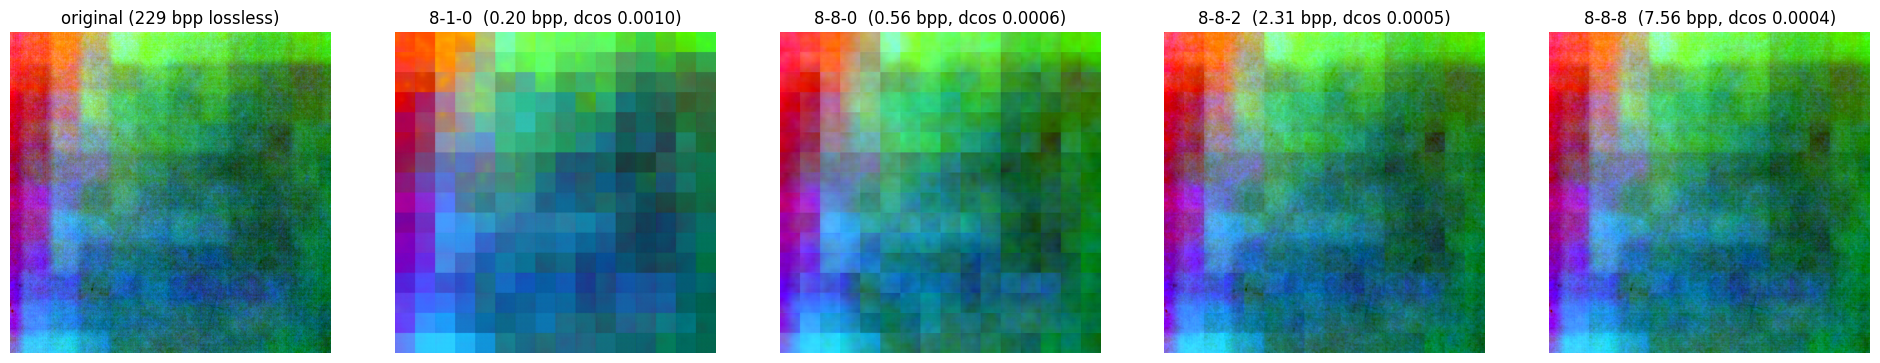

In [5]:
be = TorchBackend(BUNDLE, DEVICE)

def read_region(base, wr0, wc0, n, depths):
    """Decode an n×n-window region straight from the assets (path or
    URL — same code does local files and ranged HTTP)."""
    packets = []
    tiers = []
    for name, g, L in (("coarse", 1, depths[0]), ("mid", 4, depths[1]),
                       ("fine", 16, depths[2])):
        if L == 0:
            tiers.append(np.zeros((n*n, g*g, 0), np.int64)); continue
        with rasterio.open(f"{base}/{name}.tif") as ds:
            a = ds.read(indexes=list(range(1, L+1)),
                        window=Window(wc0*g, wr0*g, n*g, n*g))
        a = a.reshape(L, n, g, n, g).transpose(1, 3, 2, 4, 0) \
             .reshape(n*n, g*g, L)
        tiers.append(a.astype(np.int64))
    star = None
    if depths[0] == 8:
        with rasterio.open(f"{base}/star.tif") as ds:
            sg = ds.read(window=Window(wc0, wr0, n, n))
        codes = sg[:64].reshape(64, -1).T.astype(np.uint8)
        step = np.ascontiguousarray(sg[64:].reshape(2, -1).T).view(np.float16)[:, 0]
        star = unpack_star(codes, step, 1, 256)
    pk = [Packet(indices=[t[i] for t in tiers],
                 coarse_residual=star[i] if star is not None else None)
          for i in range(n*n)]
    dec = be.decode(pk, list(depths))        # (n*n, 64, 64, 64)
    return dec.reshape(n, n, 64, 64, 64).transpose(2, 0, 3, 1, 4) \
              .reshape(64, n*64, n*64)

POINTS = [(8, 1, 0), (8, 8, 0), (8, 8, 2), (8, 8, 8)]
wr0, wc0 = CROP[0]//64, CROP[1]//64
fig, ax = plt.subplots(1, 5, figsize=(24, 5.2))
ax[0].imshow(pca_rgb(x0)); ax[0].set_title("original (229 bpp lossless)")
for i, pt in enumerate(POINTS):
    rec = read_region(ASSETS, wr0, wc0, 16, pt)
    dcos = float(1 - (rec * x0).sum(0)[valid0].mean())
    bits = 8*11 + pt[1]*208 + pt[2]*3584 + (528 if pt[0] == 8 else 0)
    ax[i+1].imshow(pca_rgb(rec))
    ax[i+1].set_title(f"{pt[0]}-{pt[1]}-{pt[2]}  ({bits/4096:.2f} bpp, "
                      f"dcos {dcos:.4f})")
for a in ax: a.axis("off")

## 5. Client ↔ server

The assets are plain COGs, so "server" = any HTTP server with range
requests (here: localhost; in production: object storage + CDN) and
"client" = GDAL's `/vsicurl`. We count every byte that crosses the
wire.

- **Rate control** — *"give me this region at a fixed ladder point"*:
  the client fetches exactly the bands/blocks for that point.
- **Quality control** — *"cheapest point with p90 dcos ≤ X"*: the
  client first fetches the tile's measured stats from `metadata.json`,
  resolves the point, then fetches it.

In [6]:
import re, threading
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

WIRE = {"bytes": 0, "reqs": 0}

class RangeHandler(BaseHTTPRequestHandler):
    def log_message(self, *a): pass
    def _file(self):
        p = os.path.join(ASSETS, re.sub(r"^/cb\d+/", "", self.path).lstrip("/"))
        return p if os.path.isfile(p) else None
    def do_HEAD(self):
        f = self._file()
        if not f: self.send_error(404); return
        self.send_response(200)
        self.send_header("Content-Length", str(os.path.getsize(f)))
        self.send_header("Accept-Ranges", "bytes"); self.end_headers()
        WIRE["reqs"] += 1
    def do_GET(self):
        f = self._file()
        if not f: self.send_error(404); return
        size = os.path.getsize(f)
        m = re.match(r"bytes=(\d+)-(\d*)", self.headers.get("Range") or "")
        lo = int(m.group(1)) if m else 0
        hi = min(int(m.group(2)) if m and m.group(2) else size-1, size-1)
        with open(f, "rb") as fh:
            fh.seek(lo); data = fh.read(hi - lo + 1)
        self.send_response(206 if m else 200)
        if m: self.send_header("Content-Range", f"bytes {lo}-{hi}/{size}")
        self.send_header("Content-Length", str(len(data)))
        self.send_header("Accept-Ranges", "bytes"); self.end_headers()
        self.wfile.write(data)
        WIRE["bytes"] += len(data); WIRE["reqs"] += 1

srv = ThreadingHTTPServer(("127.0.0.1", 0), RangeHandler)   # OS-assigned port
PORT = srv.server_address[1]
threading.Thread(target=srv.serve_forever, daemon=True).start()
CB = [0]
def remote():                                # fresh prefix -> cold cache
    CB[0] += 1
    return f"/vsicurl/http://127.0.0.1:{PORT}/cb{CB[0]}"
GDAL_ENV = rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
                        CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif")
print(f"range server up on :{PORT}")

range server up on :46451


rate-control 8-8-0 viewport: 147 KiB over 92 requests  (source tile: 2,250 MiB)


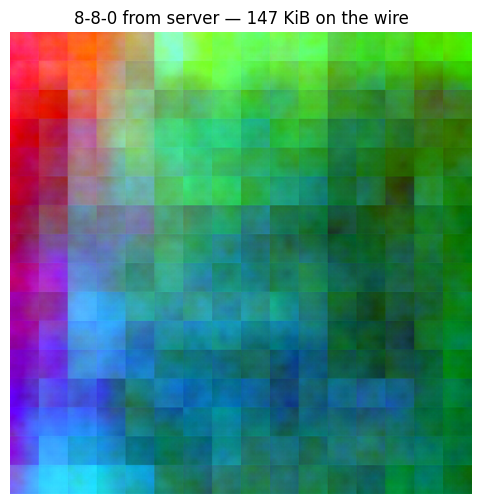

In [7]:
# --- rate control: a 1024px viewport at browse quality (8-8-0) -------
WIRE.update(bytes=0, reqs=0)
with GDAL_ENV:
    rec = read_region(remote(), wr0, wc0, 16, (8, 8, 0))
print(f"rate-control 8-8-0 viewport: {WIRE['bytes']/2**10:.0f} KiB over "
      f"{WIRE['reqs']} requests  (source tile: 2,250 MiB)")
plt.figure(figsize=(6, 6)); plt.imshow(pca_rgb(rec))
plt.title(f"8-8-0 from server — {WIRE['bytes']/2**10:.0f} KiB on the wire")
plt.axis("off");

server stats -> cheapest point with p90<=0.02: 8-8-1 (measured p90 0.0155)


quality-control viewport: 222 KiB over 97 requests


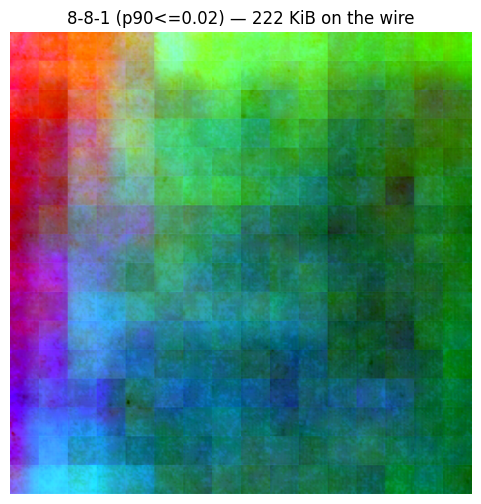

In [8]:
# --- quality control: cheapest point with p90 <= 0.02 ----------------
import urllib.request
WIRE.update(bytes=0, reqs=0)
meta = json.loads(urllib.request.urlopen(
    f"http://127.0.0.1:{PORT}/cb0/metadata.json").read())
stats = meta["quality_stats"]
point = min((v["bits"], k) for k, v in stats.items()
            if v["p90"] <= 0.02)[1]
print(f"server stats -> cheapest point with p90<=0.02: {point} "
      f"(measured p90 {stats[point]['p90']:.4f})")
depths = tuple(int(v) for v in point.split("-"))
with GDAL_ENV:
    rec = read_region(remote(), wr0, wc0, 16, depths)
print(f"quality-control viewport: {WIRE['bytes']/2**10:.0f} KiB over "
      f"{WIRE['reqs']} requests")
plt.figure(figsize=(6, 6)); plt.imshow(pca_rgb(rec))
plt.title(f"{point} (p90<=0.02) — {WIRE['bytes']/2**10:.0f} KiB on the wire")
plt.axis("off");

## 6. Two decoders, one bitstream

Windows decode independently, so the base decoder leaves faint seams at
every 64 px boundary. The release ships a second decoder — **`deblock`**
(`georvq-ae-tile decode --decoder deblock`) — that removes them: a
2 M-param conditioned UNet applied by a **canonical recipe**: 512 px
frames anchored at the tile origin, each deblocked with a one-window
(64 px) halo, hard-cropped back. The recipe constants are hashed into
the decoder's `decoder_id`, so a deblocked pixel is a pure function of
the code indices within 64 px of its frame — every client, scheduler
and viewport decode produces the same field.

Our viewport happens to be 2×2 canonical frames. We fetch **one extra
window ring** (the locality contract's support) and deblock each frame
exactly as the CLI would — this is all a ranged-read client needs.

deblock decoder fba6e990f327dc75  recipe {'frame': 512, 'halo': 64, 'blend': 'crop', 'version': 1}


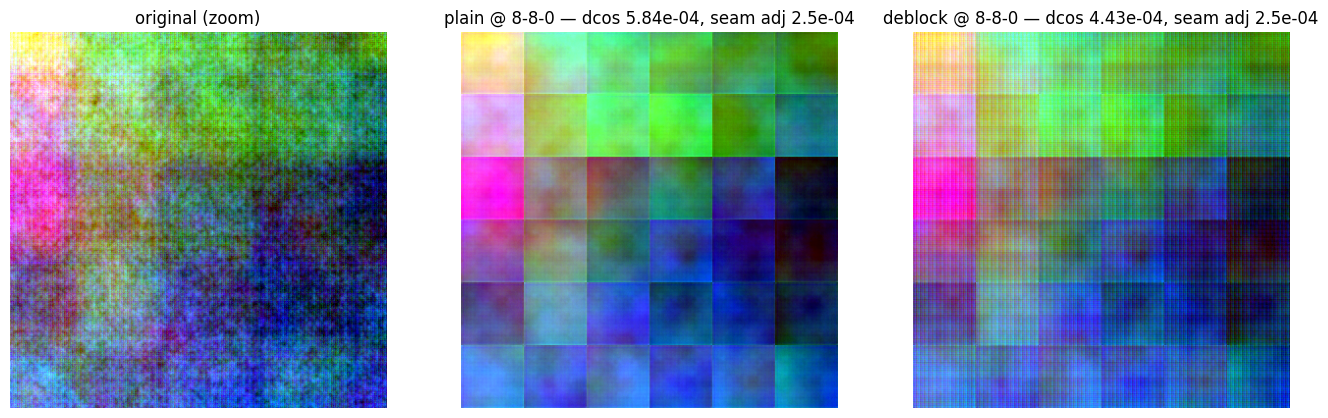

In [9]:
from georvq.ae.deblock import RECIPE
be.load_deblock()
print(f"deblock decoder {be.deblock_decoder_id}  recipe {RECIPE}")

PT = (8, 8, 0)                               # browse rate: seams visible
plain = read_region(ASSETS, wr0, wc0, 16, PT)
sup = read_region(ASSETS, wr0 - 1, wc0 - 1, 18, PT)  # +1-window halo ring
FR, HA = RECIPE["frame"], RECIPE["halo"]
deblocked = np.empty_like(plain)
for r0 in range(0, 1024, FR):                # crop is frame-aligned here
    for c0 in range(0, 1024, FR):
        y = be.deblock_frame(sup[:, r0:r0 + FR + 2*HA, c0:c0 + FR + 2*HA],
                             PT)
        deblocked[:, r0:r0 + FR, c0:c0 + FR] = y[:, HA:HA + FR,
                                                 HA:HA + FR]

def win_seam_adj(x):
    """Mean adjacency dcos across 64 px window boundaries."""
    win = (np.arange(1, x.shape[-1]) % 64) == 0
    dh = 1 - (x[:, :, :-1] * x[:, :, 1:]).sum(0)
    dv = 1 - (x[:, :-1, :] * x[:, 1:, :]).sum(0)
    return float((dh[:, win].mean() + dv[win, :].mean()) / 2)

Z = np.s_[:, 256:640, 256:640]               # 384px zoom
fig, ax = plt.subplots(1, 3, figsize=(16.5, 5.8))
for a, img, name in ((ax[0], x0, "original"), (ax[1], plain, "plain"),
                     (ax[2], deblocked, "deblock")):
    a.imshow(pca_rgb(img[Z])); a.axis("off")
    if name == "original":
        a.set_title("original (zoom)")
    else:
        d = float(1 - (img * x0).sum(0)[valid0].mean())
        a.set_title(f"{name} @ {'-'.join(map(str, PT))} — dcos {d:.2e}, "
                    f"seam adj {win_seam_adj(img):.1e}")

### Each decoder carries its own quality layer

Decoder variants publish *separately measured* error metadata under
their `decoder_id` — same blobs, different `quality/<decoder_id>.tif` +
stats namespace, all minted server-side with the identical canonical
routine. Pre-existing tiles upgrade in place (no index byte changes):

```bash
georvq-ae-tile restat --model <bundle> --device cuda <tile_dir> <source.tiff>
```

The payoff of anchoring the second quality layer: the **same quality
bound resolves to a cheaper ladder point** under the better decoder —
`--quality` + `--decoder deblock` composes into real rate savings.

In [10]:
meta = json.load(open(f"{ASSETS}/metadata.json"))
# bound = the best the plain decoder can do on THIS tile (its measured
# full-ladder mean) — plain resolves it at full rate by construction;
# the question is what the deblock decoder pays for the same bound
full = max(meta["quality_stats"], key=lambda k: meta["quality_stats"][k]["bits"])
BOUND = ("mean", meta["quality_stats"][full]["mean"])

def resolve(stats):
    ok = [(v["bits"], k) for k, v in stats.items()
          if v[BOUND[0]] <= BOUND[1]]
    return min(ok) if ok else (None, "unreachable")

bits_p, pt_p = resolve(meta["quality_stats"])
print(f"{BOUND[0]} <= {BOUND[1]:.3e} (plain's measured best):")
print(f"  plain    -> {pt_p:8s} {bits_p:8.0f} bits/window")
if meta.get("decoders"):
    for did, e in meta["decoders"].items():
        bits_d, pt_d = resolve(e["quality_stats"])
        print(f"  {e['name']:8s} -> {pt_d:8s} {bits_d:8.0f} bits/window "
              f"({bits_p / bits_d:.1f}x fewer bits, decoder {did})")
else:
    print("  (no variant-decoder stats on this tile yet — mint them "
          "with the restat command above)")

mean <= 2.817e-03 (plain's measured best):
  plain    -> 8-8-8       30952 bits/window
  deblock  -> 8-8-4       16616 bits/window (1.9x fewer bits, decoder fba6e990f327dc75)


## Wrap-up

- **~40× smaller** than the already-compressed source (2,250 → 58 MiB)
  at cosine fidelity 0.998, exact nodata + georeferencing round-trip.
- **Progressive**: one archive serves 0.07 → 7.4 bpp; whole-tile coarse
  browse is ~180 KiB.
- **It's just COGs**: rasterio/GDAL/QGIS/STAC tooling works out of the
  box; windowed region access costs KiB, not GiB.
- **Self-measuring**: every tile carries its true error statistics per
  rate point — quality-controlled delivery instead of hope.
- **Two decoders, one archive**: the deblock decoder removes window
  seams under a canonical, hashed recipe (mean error −40% at full
  rate) — same blobs, separately measured quality layers.

Codec: `georvq` (frozen release `ae_pyr64_divfull`, bitstream
`2f7c3527…`). Encoder/decoder run via PyTorch (GPU/CPU) or ONNX
(torch-free).